### K-Means Clustering

#### 1. Chuẩn bị vấn đề

##### 1.1 Khai báo thư viện

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "axes.titlesize": 13, "figure.dpi": 120})

CLR = {"ngheo": "#C82333", "can": "#F8E71C",
       "sig": "#2EAF7D", "ns": "#AAAAAA"}

pd.set_option("display.max_columns", 80)


##### 1.2 Cấu hình đường dẫn và biến đầu vào


In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

INPUT_PATH = ROOT / "data" / "model" / "household_featured.xlsx"
OUTPUT_DIR = ROOT / "data" / "model"
CLUSTERED_PATH = OUTPUT_DIR / "household_clustered.xlsx"
PROFILE_PATH = OUTPUT_DIR / "cluster_profile.xlsx"

RANDOM_STATE = 42

# Không gán FINAL_K trước khi đánh giá. Các ngưỡng dưới đây là tiêu chí chọn mô hình
# được công bố trước khi xem kết quả, nhằm tránh chọn k theo cảm tính.
K_VALUES = range(2, 9)
K_REPEATS = 5
SILHOUETTE_REPEATS = 3
SILHOUETTE_TOLERANCE = 0.02
MIN_STABILITY_ARI = 0.80
MIN_CLUSTER_SHARE = 0.03
FINAL_K = None

FEATURE_COLUMNS = [
    "NHAN_KHAU",
    "SO_MAM_NON",
    "SO_HOC_DUONG",
    "SO_LAO_DONG",
    "SO_U50",
    "SO_PHU_THUOC",
    "TY_LE_MAM_NON",
    "TY_LE_HOC_DUONG",
    "TY_LE_LAO_DONG",
    "TY_LE_U50",
    "TY_LE_PHU_THUOC",
    "TUOI_CHU_HO",
    "TUOI_TRUNG_BINH_HO",
    "TUOI_LON_NHAT",
    "TUOI_NHO_NHAT",
    "DO_LECH_TUOI",
]

ID_COLUMNS = [
    "HOUSEHOLD_ID",
    "STT_HO",
    "HUYEN",
    "XA",
    "PHAN_LOAI_HO",
    "HO_TEN_CHU_HO",
]

CLUSTER_NAMES = {
    "aging_dependency": "Hộ già hóa và phụ thuộc cao",
    "education_burden": "Hộ đông con và gánh nặng giáo dục",
    "livelihood_vulnerable": "Hộ cận nghèo và dễ tổn thương sinh kế",
}


##### 1.3 Đọc dữ liệu

In [3]:
# Hàm load_data: đọc file household_featured.xlsx làm dữ liệu đầu vào cho tầng 4.
def load_data(path: Path = INPUT_PATH) -> pd.DataFrame:
    return pd.read_excel(path)


##### 1.4 Load dữ liệu


In [4]:
df = load_data()
print(df.shape)
df.head()


(26953, 34)


,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,NHAN_KHAU,NHAN_KHAU_GOC_MAX,SO_CHU_HO,SO_XA_TRONG_HO,SO_HUYEN_TRONG_HO,CO_DONG_CHU_HO,SOURCE_ROW_MIN,SOURCE_ROW_MAX,SO_NAM,SO_NU,SO_MAM_NON,SO_HOC_DUONG,SO_LAO_DONG,SO_U50,SO_PHU_THUOC,TY_LE_MAM_NON,TY_LE_HOC_DUONG,TY_LE_LAO_DONG,TY_LE_U50,TY_LE_PHU_THUOC,HO_TEN_CHU_HO,TUOI_CHU_HO,GIOI_TINH_CHU_HO,DAN_TOC_CHU_HO,NHOM_TUOI_CHU_HO,TUOI_TRUNG_BINH_HO,TUOI_LON_NHAT,TUOI_NHO_NHAT,DO_LECH_TUOI
0,1,1,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,1,1.0,1,1,1,1,1,1,0,1,0,0,0,1,1,0.0,0.0,0.000000,1.000000,NaN,TRƯƠNG THỊ LÙN,87.0,Nữ,Kinh,65+,87.000000,87.0,87.0,0.0
1,2,2,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,4,4.0,1,1,1,1,2,5,2,2,0,2,2,0,2,0.0,0.5,0.500000,0.000000,1.0,HOÀNG VĂN TRƯỜNG,46.0,Nam,Kinh,35-49,29.750000,46.0,13.0,33.0
2,3,3,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,2,2.0,1,1,1,1,6,7,1,1,0,0,0,2,2,0.0,0.0,0.000000,1.000000,NaN,TRẦN VĂN LONG,66.0,Nam,Kinh,65+,60.500000,66.0,55.0,11.0
3,4,4,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,1,1.0,1,1,1,1,8,8,0,1,0,0,0,1,1,0.0,0.0,0.000000,1.000000,NaN,NGUYỄN THỊ TƯƠI,80.0,Nữ,Kinh,65+,80.000000,80.0,80.0,0.0
4,5,5,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,6,6.0,1,1,1,1,9,14,1,5,0,3,1,2,5,0.0,0.5,0.166667,0.333333,5.0,ĐỖ VĂN PHÚC,66.0,Nam,Kinh,65+,33.333333,66.0,10.0,56.0


##### 1.5 Câu hỏi nghiên cứu

- Sau khi thử nhiều giá trị `k`, số cụm nào cân bằng tốt nhất giữa chất lượng, độ ổn định và khả năng diễn giải?
- Với số cụm được chọn, các hộ dân được phân thành những cụm đặc trưng nào?
- Mỗi cụm nổi bật ở những biến nhân khẩu, giáo dục, lao động, tuổi và phụ thuộc nào?
- Cụm nào thể hiện dấu hiệu già hóa, gánh nặng giáo dục hoặc dễ tổn thương sinh kế?
- Các cụm liên hệ thế nào với `PHAN_LOAI_HO` và địa bàn?


____
#### 2. Kiểm tra dữ liệu và giá trị bất thường

##### 2.1 Kiểm tra missing value

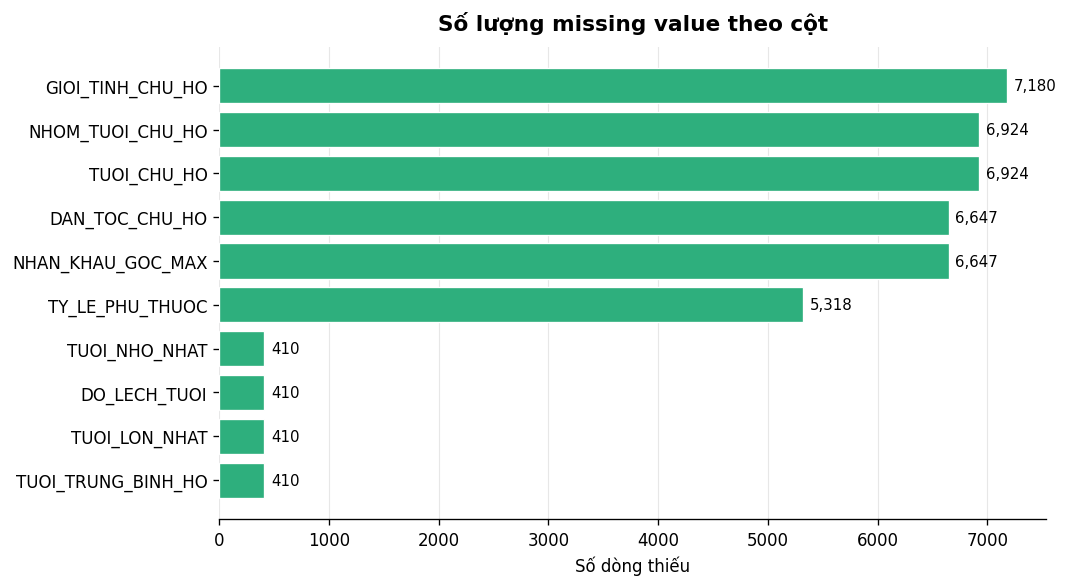

,column,missing_count
27,GIOI_TINH_CHU_HO,7180
26,TUOI_CHU_HO,6924
29,NHOM_TUOI_CHU_HO,6924
6,NHAN_KHAU_GOC_MAX,6647
28,DAN_TOC_CHU_HO,6647
24,TY_LE_PHU_THUOC,5318
31,TUOI_LON_NHAT,410
30,TUOI_TRUNG_BINH_HO,410
33,DO_LECH_TUOI,410
32,TUOI_NHO_NHAT,410


In [5]:
missing_df = (
    df.isna().sum()
    .reset_index(name="missing_count")
    .rename(columns={"index": "column"})
)
missing_df = missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=True)

fig, ax = plt.subplots(figsize=(9, max(3.5, 0.38 * len(missing_df) + 1.2)))
bars = ax.barh(
    missing_df["column"],
    missing_df["missing_count"],
    color=CLR["sig"],
    edgecolor="white",
    linewidth=0.8,
)
ax.set_title("Số lượng missing value theo cột", pad=10, fontweight="bold")
ax.set_xlabel("Số dòng thiếu")
ax.grid(axis="x", color=CLR["ns"], alpha=0.28, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=9)
plt.tight_layout()
plt.show()

missing_df.sort_values("missing_count", ascending=False)


##### 2.2 Thống kê mô tả biến số

In [6]:
numeric_cols = [col for col in FEATURE_COLUMNS if col in df.columns]
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
NHAN_KHAU,26953.0,3.653693,2.183086,1.0,2.000000,4.00,5.000000,21.0
SO_MAM_NON,26953.0,0.077283,0.280991,0.0,0.000000,0.00,0.000000,3.0
SO_HOC_DUONG,26953.0,1.176344,1.239662,0.0,0.000000,1.00,2.000000,11.0
SO_LAO_DONG,26953.0,1.806738,1.398945,0.0,1.000000,2.00,3.000000,11.0
SO_U50,26953.0,0.523578,0.757795,0.0,0.000000,0.00,1.000000,5.0
SO_PHU_THUOC,26953.0,1.777205,1.369362,0.0,1.000000,2.00,2.000000,13.0
TY_LE_MAM_NON,26953.0,0.021172,0.099434,0.0,0.000000,0.00,0.000000,1.0
TY_LE_HOC_DUONG,26953.0,0.297836,0.304292,0.0,0.000000,0.25,0.500000,1.0
TY_LE_LAO_DONG,26953.0,0.478432,0.318835,0.0,0.285714,0.50,0.666667,1.0
TY_LE_U50,26953.0,0.179234,0.299528,0.0,0.000000,0.00,0.250000,1.0


##### 2.3 Kiểm tra giá trị bất thường bằng boxplot

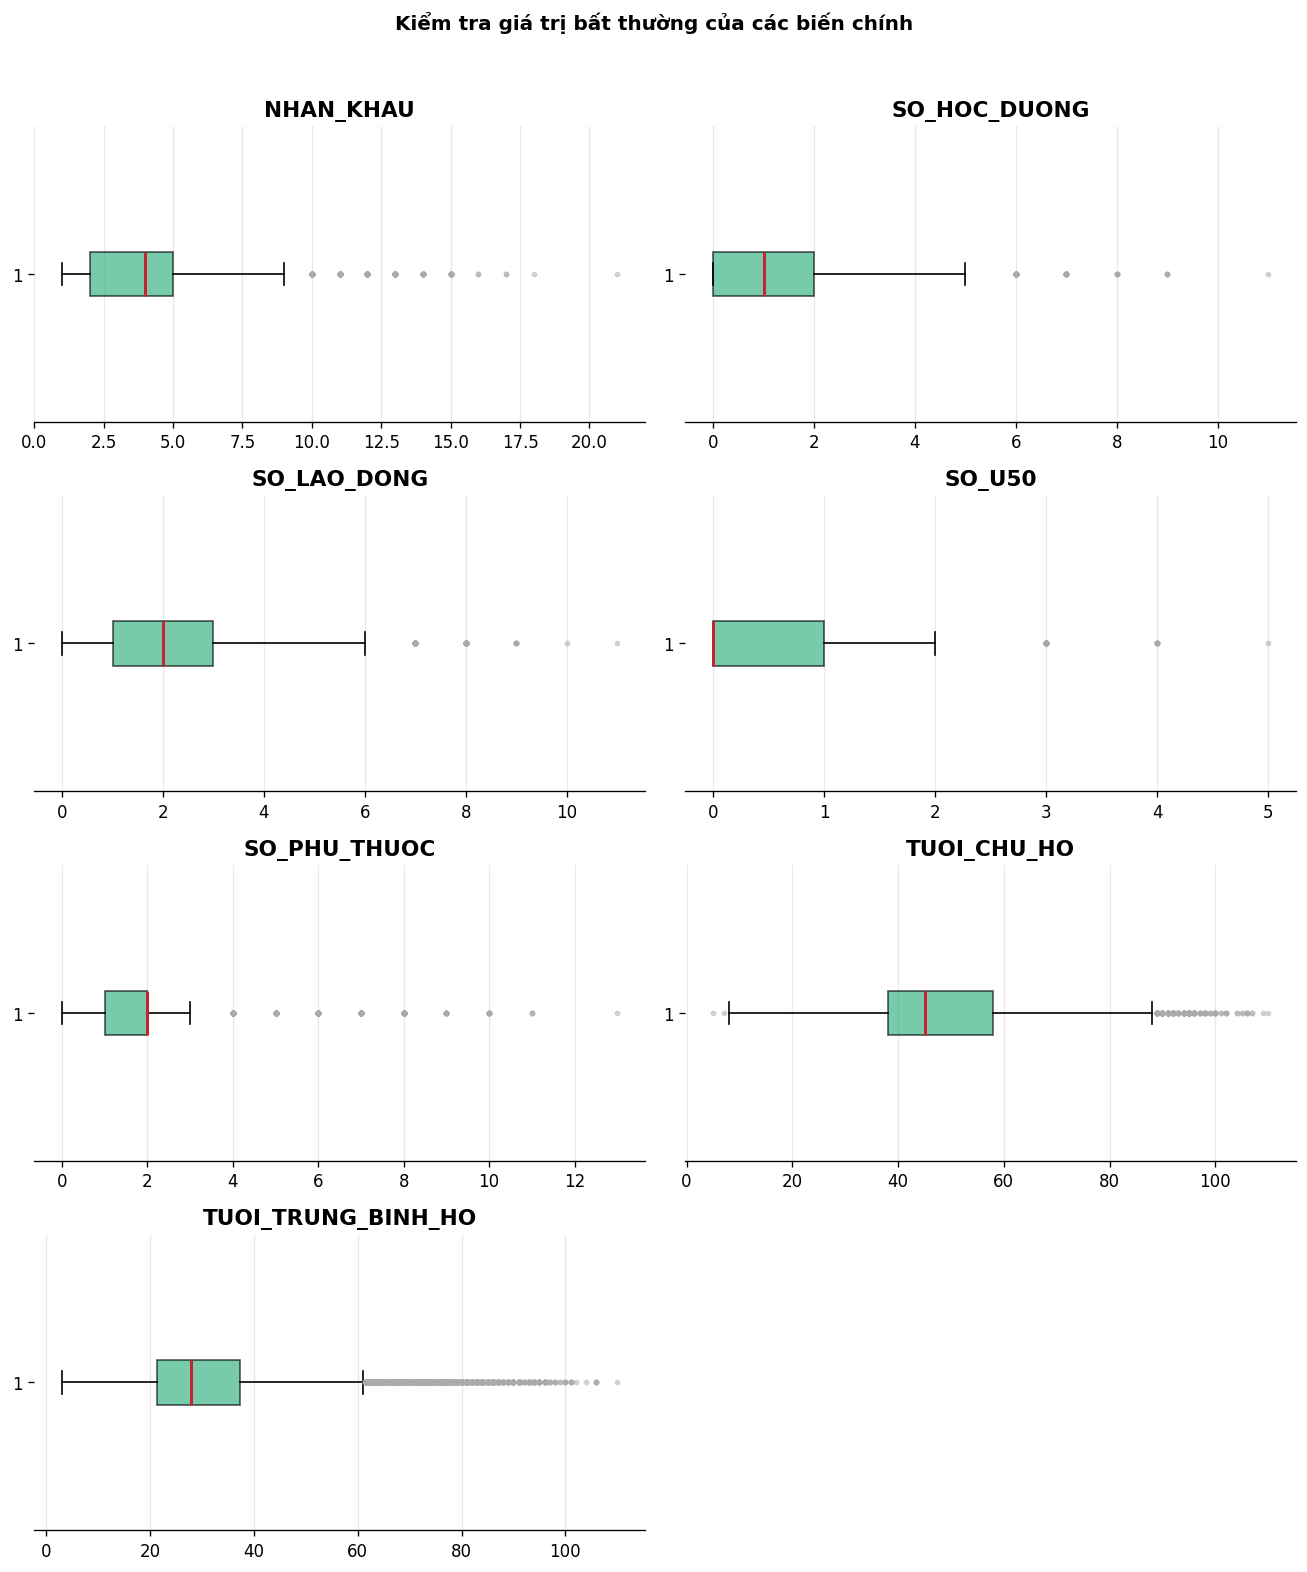

In [7]:
check_cols = [
    "NHAN_KHAU",
    "SO_HOC_DUONG",
    "SO_LAO_DONG",
    "SO_U50",
    "SO_PHU_THUOC",
    "TUOI_CHU_HO",
    "TUOI_TRUNG_BINH_HO",
]
check_cols = [col for col in check_cols if col in df.columns]

n_cols = 2
n_rows = int(np.ceil(len(check_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 3.2 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, check_cols):
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    ax.boxplot(values, vert=False, patch_artist=True,
               boxprops={"facecolor": CLR["sig"], "alpha": 0.65},
               medianprops={"color": CLR["ngheo"], "linewidth": 1.8},
               flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": CLR["ns"], "markeredgecolor": CLR["ns"], "alpha": 0.45})
    ax.set_title(col, fontweight="bold")
    ax.grid(axis="x", color=CLR["ns"], alpha=0.25)
    ax.spines[["top", "right", "left"]].set_visible(False)

for ax in axes[len(check_cols):]:
    ax.axis("off")

plt.suptitle("Kiểm tra giá trị bất thường của các biến chính", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


**Nhận xét:**
- Phần lớn hộ có khoảng 2–5 nhân khẩu, 1–3 lao động, 0–2 người học đường, 0–2 người phụ thuộc và tối đa khoảng 1 người trên 50 tuổi. Tuy nhiên, các biến đếm đều xuất hiện ngoại lệ ở phía giá trị cao, như hộ trên 10 nhân khẩu, hơn 6 lao động, trên 5 người học đường hoặc trên 4 người phụ thuộc. Với biến tuổi, chủ hộ chủ yếu nằm trong khoảng 40–60 tuổi, còn tuổi trung bình hộ khoảng 20–40 tuổi, nhưng vẫn có một số trường hợp rất cao, gần hoặc trên 100 tuổi, cần được rà soát thêm.

#### 3. Scale lại dữ liệu

#### 3.1 Chọn biến và xử lý missing value

In [8]:
# Hàm prepare_features: chọn biến phân cụm, ép kiểu số và xử lý missing value.
def prepare_features(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    missing_cols = [col for col in FEATURE_COLUMNS if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing feature columns: {missing_cols}")

    features = df[FEATURE_COLUMNS].copy()
    features = features.apply(pd.to_numeric, errors="coerce")

    # The dependency ratio is undefined when a household has no working-age labor.
    # Keep that signal by using the dependent count instead of a neutral median.
    zero_labor_mask = features["SO_LAO_DONG"].eq(0) & features["TY_LE_PHU_THUOC"].isna()
    features.loc[zero_labor_mask, "TY_LE_PHU_THUOC"] = features.loc[zero_labor_mask, "SO_PHU_THUOC"]

    medians = features.median(numeric_only=True)
    features = features.fillna(medians)
    return features, medians


#### 3.2 Chuẩn chuẩn hóa dữ liệu

In [9]:
# Hàm standardize: chuẩn hóa các biến về cùng thang đo theo công thức z-score.
def standardize(features: pd.DataFrame) -> tuple[np.ndarray, pd.Series, pd.Series]:
    means = features.mean()
    stds = features.std(ddof=0).replace(0, 1)
    scaled = ((features - means) / stds).to_numpy(dtype=np.float64)
    return scaled, means, stds


#### 3.3 Tạo ma trận dữ liệu sau xử lý

Tạo `features`, lưu median dùng để điền thiếu và tạo ma trận `scaled` cho K-Means.


In [10]:
features, medians = prepare_features(df)
scaled, feature_means, feature_stds = standardize(features)

display(features.describe().T)
display(medians.rename("median_imputed_value").to_frame())


,count,mean,std,min,25%,50%,75%,max
NHAN_KHAU,26953.0,3.653693,2.183086,1.0,2.000000,4.00,5.000000,21.0
SO_MAM_NON,26953.0,0.077283,0.280991,0.0,0.000000,0.00,0.000000,3.0
SO_HOC_DUONG,26953.0,1.176344,1.239662,0.0,0.000000,1.00,2.000000,11.0
SO_LAO_DONG,26953.0,1.806738,1.398945,0.0,1.000000,2.00,3.000000,11.0
SO_U50,26953.0,0.523578,0.757795,0.0,0.000000,0.00,1.000000,5.0
SO_PHU_THUOC,26953.0,1.777205,1.369362,0.0,1.000000,2.00,2.000000,13.0
TY_LE_MAM_NON,26953.0,0.021172,0.099434,0.0,0.000000,0.00,0.000000,1.0
TY_LE_HOC_DUONG,26953.0,0.297836,0.304292,0.0,0.000000,0.25,0.500000,1.0
TY_LE_LAO_DONG,26953.0,0.478432,0.318835,0.0,0.285714,0.50,0.666667,1.0
TY_LE_U50,26953.0,0.179234,0.299528,0.0,0.000000,0.00,0.250000,1.0


,median_imputed_value
NHAN_KHAU,4.00
SO_MAM_NON,0.00
SO_HOC_DUONG,1.00
SO_LAO_DONG,2.00
SO_U50,0.00
SO_PHU_THUOC,2.00
TY_LE_MAM_NON,0.00
TY_LE_HOC_DUONG,0.25
TY_LE_LAO_DONG,0.50
TY_LE_U50,0.00


#### 3.4 Trực quan giá trị trung bình biến đầu vào

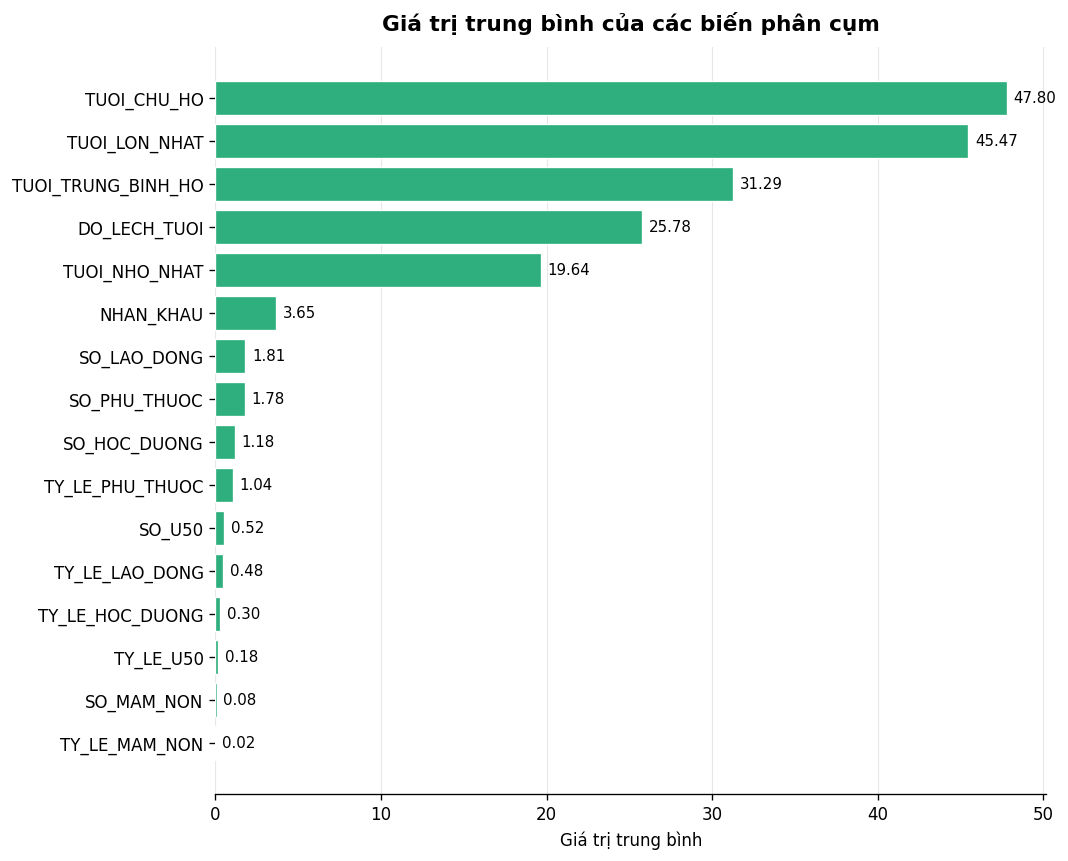

In [11]:
feature_mean_df = (
    features.mean()
    .reset_index(name="mean_value")
    .rename(columns={"index": "feature"})
    .sort_values("mean_value", ascending=True)
)

fig, ax = plt.subplots(figsize=(9, max(3.5, 0.38 * len(feature_mean_df) + 1.2)))
bars = ax.barh(
    feature_mean_df["feature"],
    feature_mean_df["mean_value"],
    color=CLR["sig"],
    edgecolor="white",
    linewidth=0.8,
)
ax.set_title("Giá trị trung bình của các biến phân cụm", pad=10, fontweight="bold")
ax.set_xlabel("Giá trị trung bình")
ax.grid(axis="x", color=CLR["ns"], alpha=0.28, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(bars, fmt="{:,.2f}", padding=4, fontsize=9)
plt.tight_layout()
plt.show()


**Nhận xét:**
- Các hộ có trung bình 3,65 nhân khẩu, gồm khoảng 1,81 lao động, 1,78 người phụ thuộc và 1,18 người trong độ tuổi học đường. Tuổi chủ hộ trung bình là 47,8 tuổi, trong khi tuổi trung bình của hộ khoảng 31,29 tuổi, cho thấy cơ cấu hộ có sự kết hợp giữa người trưởng thành và nhóm phụ thuộc.

#### 4. K-Means Clustering

#### 4.1 Huấn luyện K-Means

In [12]:
# Hàm init_centroids_kmeans_plus_plus: khởi tạo tâm cụm ban đầu theo K-Means++ để mô hình ổn định hơn.
def init_centroids_kmeans_plus_plus(x: np.ndarray, k: int, rng: np.random.Generator) -> np.ndarray:
    n_rows = x.shape[0]
    centroids = np.empty((k, x.shape[1]), dtype=np.float64)
    first_idx = rng.integers(n_rows)
    centroids[0] = x[first_idx]

    closest_dist_sq = np.sum((x - centroids[0]) ** 2, axis=1)
    for centroid_idx in range(1, k):
        total = closest_dist_sq.sum()
        if not np.isfinite(total) or total == 0:
            centroids[centroid_idx] = x[rng.integers(n_rows)]
            continue

        probs = closest_dist_sq / total
        chosen_idx = rng.choice(n_rows, p=probs)
        centroids[centroid_idx] = x[chosen_idx]
        new_dist_sq = np.sum((x - centroids[centroid_idx]) ** 2, axis=1)
        closest_dist_sq = np.minimum(closest_dist_sq, new_dist_sq)

    return centroids


def fit_kmeans(
    x: np.ndarray,
    k: int,
    n_init: int = 10,
    max_iter: int = 300,
    tol: float = 1e-4,
    random_state: int = RANDOM_STATE,
) -> tuple[np.ndarray, np.ndarray, float]:
    best_labels: np.ndarray | None = None
    best_centroids: np.ndarray | None = None
    best_inertia = np.inf

    base_rng = np.random.default_rng(random_state)
    seeds = base_rng.integers(0, np.iinfo(np.int32).max, size=n_init)

    for seed in seeds:
        rng = np.random.default_rng(int(seed))
        centroids = init_centroids_kmeans_plus_plus(x, k, rng)

        for _ in range(max_iter):
            dist_sq = squared_distances_to_centroids(x, centroids)
            labels = dist_sq.argmin(axis=1)

            new_centroids = centroids.copy()
            for cluster_id in range(k):
                mask = labels == cluster_id
                if mask.any():
                    new_centroids[cluster_id] = x[mask].mean(axis=0)
                else:
                    farthest_idx = dist_sq.min(axis=1).argmax()
                    new_centroids[cluster_id] = x[farthest_idx]

            shift = np.sqrt(((centroids - new_centroids) ** 2).sum(axis=1)).max()
            centroids = new_centroids
            if shift <= tol:
                break

        dist_sq = squared_distances_to_centroids(x, centroids)
        labels = dist_sq.argmin(axis=1)
        inertia = float(dist_sq[np.arange(x.shape[0]), labels].sum())

        if inertia < best_inertia:
            best_inertia = inertia
            best_labels = labels.copy()
            best_centroids = centroids.copy()

    if best_labels is None or best_centroids is None:
        raise RuntimeError("K-Means failed to produce a fitted model.")

    return best_labels, best_centroids, best_inertia


def squared_distances_to_centroids(x: np.ndarray, centroids: np.ndarray) -> np.ndarray:
    return ((x[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)


##### 4.2 Đánh giá số cụm


In [13]:
# Tính Silhouette trên mẫu để đánh giá nhanh chất lượng cụm.
def silhouette_score_sample(
    x: np.ndarray,
    labels: np.ndarray,
    sample_size: int = 1200,
    random_state: int = RANDOM_STATE,
    chunk_size: int = 200,
) -> float:
    unique_labels = np.sort(np.unique(labels))
    if len(unique_labels) < 2:
        return np.nan

    rng = np.random.default_rng(random_state)
    sample_size = min(sample_size, x.shape[0])
    sample_idx = rng.choice(x.shape[0], size=sample_size, replace=False)
    sample = x[sample_idx]
    sample_labels = labels[sample_idx]

    cluster_counts = {cluster_id: int((labels == cluster_id).sum()) for cluster_id in unique_labels}
    silhouettes: list[np.ndarray] = []

    for start in range(0, sample_size, chunk_size):
        stop = min(start + chunk_size, sample_size)
        chunk = sample[start:stop]
        chunk_labels = sample_labels[start:stop]
        distances = np.sqrt(((chunk[:, None, :] - x[None, :, :]) ** 2).sum(axis=2))

        mean_by_cluster = np.empty((chunk.shape[0], len(unique_labels)), dtype=np.float64)
        for pos, cluster_id in enumerate(unique_labels):
            mask = labels == cluster_id
            mean_by_cluster[:, pos] = distances[:, mask].sum(axis=1) / cluster_counts[cluster_id]

        own_positions = np.array([np.where(unique_labels == lab)[0][0] for lab in chunk_labels])
        a = mean_by_cluster[np.arange(chunk.shape[0]), own_positions]

        for row_idx, lab in enumerate(chunk_labels):
            if cluster_counts[lab] > 1:
                a[row_idx] = a[row_idx] * cluster_counts[lab] / (cluster_counts[lab] - 1)
            else:
                a[row_idx] = 0.0

        mean_by_cluster[np.arange(chunk.shape[0]), own_positions] = np.inf
        b = mean_by_cluster.min(axis=1)
        denom = np.maximum(a, b)
        silhouettes.append(np.where(denom > 0, (b - a) / denom, 0.0))

    return float(np.concatenate(silhouettes).mean())


def adjusted_rand_index(labels_a: np.ndarray, labels_b: np.ndarray) -> float:
    """Adjusted Rand Index, không phụ thuộc tên/hoán vị của nhãn cụm."""
    _, a = np.unique(labels_a, return_inverse=True)
    _, b = np.unique(labels_b, return_inverse=True)
    contingency = np.zeros((a.max() + 1, b.max() + 1), dtype=np.int64)
    np.add.at(contingency, (a, b), 1)

    comb2 = lambda values: (values * (values - 1) / 2).sum()
    index = comb2(contingency)
    row_pairs = comb2(contingency.sum(axis=1))
    col_pairs = comb2(contingency.sum(axis=0))
    total_pairs = len(labels_a) * (len(labels_a) - 1) / 2
    expected = row_pairs * col_pairs / total_pairs if total_pairs else 0.0
    maximum = 0.5 * (row_pairs + col_pairs)
    return float((index - expected) / (maximum - expected)) if maximum != expected else 1.0


def evaluate_k_range(x: np.ndarray, k_values=K_VALUES) -> pd.DataFrame:
    """Đánh giá mỗi k qua nhiều lần fit và nhiều mẫu Silhouette."""
    rows = []
    for k in k_values:
        fitted = []
        for repeat in range(K_REPEATS):
            labels, centroids, inertia = fit_kmeans(
                x,
                k=k,
                n_init=4,
                random_state=RANDOM_STATE + 1000 * k + repeat,
            )
            fitted.append((labels, centroids, inertia))

        inertias = np.array([result[2] for result in fitted])
        best_idx = int(inertias.argmin())
        best_labels = fitted[best_idx][0]
        stability = [
            adjusted_rand_index(best_labels, result[0])
            for idx, result in enumerate(fitted)
            if idx != best_idx
        ]
        silhouette_scores = [
            silhouette_score_sample(
                x,
                best_labels,
                random_state=RANDOM_STATE + 10000 * k + repeat,
            )
            for repeat in range(SILHOUETTE_REPEATS)
        ]
        shares = np.bincount(best_labels, minlength=k) / len(best_labels)

        rows.append({
            "k": k,
            "inertia_best": inertias.min(),
            "inertia_mean": inertias.mean(),
            "inertia_std": inertias.std(ddof=1),
            "silhouette_mean": np.mean(silhouette_scores),
            "silhouette_std": np.std(silhouette_scores, ddof=1),
            "stability_ari_mean": np.mean(stability),
            "stability_ari_min": np.min(stability),
            "min_cluster_share": shares.min(),
        })
    return pd.DataFrame(rows)


def detect_elbow(diagnostics: pd.DataFrame) -> int:
    """Chọn điểm xa nhất so với đường nối hai đầu của đường Inertia chuẩn hóa."""
    x = diagnostics["k"].to_numpy(dtype=float)
    y = diagnostics["inertia_best"].to_numpy(dtype=float)
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    distance_below_line = (1 - x_norm) - y_norm
    return int(x[np.argmax(distance_below_line)])


def select_k(diagnostics: pd.DataFrame) -> tuple[int, int, pd.Series]:
    """Chọn k nhỏ nhất đạt chất lượng gần tốt nhất và qua các ràng buộc."""
    elbow_k = detect_elbow(diagnostics)
    best_silhouette = diagnostics["silhouette_mean"].max()
    eligible = diagnostics.loc[
        (diagnostics["k"] >= elbow_k)
        & (diagnostics["silhouette_mean"] >= best_silhouette - SILHOUETTE_TOLERANCE)
        & (diagnostics["stability_ari_mean"] >= MIN_STABILITY_ARI)
        & (diagnostics["min_cluster_share"] >= MIN_CLUSTER_SHARE)
    ]

    if eligible.empty:
        # Nếu không k nào qua toàn bộ ràng buộc, chọn phương án khả thi có
        # Silhouette cao nhất và báo rõ để người đọc không hiểu nhầm.
        feasible = diagnostics.loc[
            (diagnostics["stability_ari_mean"] >= MIN_STABILITY_ARI)
            & (diagnostics["min_cluster_share"] >= MIN_CLUSTER_SHARE)
        ]
        pool = feasible if not feasible.empty else diagnostics
        selected = pool.loc[pool["silhouette_mean"].idxmax()]
    else:
        selected = eligible.sort_values("k").iloc[0]

    return int(selected["k"]), elbow_k, selected


##### 4.3 Chạy đánh giá nhiều giá trị k


In [14]:
diagnostics = evaluate_k_range(scaled)
FINAL_K, elbow_k, selected_row = select_k(diagnostics)

diagnostics_display = diagnostics.copy()
for column in ["inertia_best", "inertia_mean", "inertia_std"]:
    diagnostics_display[column] = diagnostics_display[column].round(2)
for column in ["silhouette_mean", "silhouette_std", "stability_ari_mean", "stability_ari_min", "min_cluster_share"]:
    diagnostics_display[column] = diagnostics_display[column].round(4)

best_silhouette_row = diagnostics.loc[diagnostics["silhouette_mean"].idxmax()]

print("Bảng đánh giá số cụm qua nhiều lần chạy")
print(f"- Khoảng k đã thử: {min(K_VALUES)}–{max(K_VALUES)}")
print(f"- Mỗi k được fit {K_REPEATS} lần; Silhouette được lấy mẫu {SILHOUETTE_REPEATS} lần")
print(f"- Elbow xác định tự động: k={elbow_k}")
print(f"- Silhouette trung bình cao nhất: k={int(best_silhouette_row['k'])} "
      f"({best_silhouette_row['silhouette_mean']:.4f})")
print(f"- k được chọn: {FINAL_K} "
      f"(Silhouette={selected_row['silhouette_mean']:.4f}, "
      f"ARI={selected_row['stability_ari_mean']:.4f}, "
      f"cụm nhỏ nhất={selected_row['min_cluster_share']:.2%})")
print("- Quy tắc: chọn k nhỏ nhất từ điểm elbow, có Silhouette cách mức tốt nhất không quá "
      f"{SILHOUETTE_TOLERANCE:.2f}, ARI ≥ {MIN_STABILITY_ARI:.2f}, "
      f"và cụm nhỏ nhất ≥ {MIN_CLUSTER_SHARE:.0%}.")

display(diagnostics_display)


Bảng đánh giá số cụm qua nhiều lần chạy
- Khoảng k đã thử: 2–8
- Mỗi k được fit 5 lần; Silhouette được lấy mẫu 3 lần
- Elbow xác định tự động: k=5
- Silhouette trung bình cao nhất: k=7 (0.3731)
- k được chọn: 7 (Silhouette=0.3731, ARI=0.9995, cụm nhỏ nhất=6.40%)
- Quy tắc: chọn k nhỏ nhất từ điểm elbow, có Silhouette cách mức tốt nhất không quá 0.02, ARI ≥ 0.80, và cụm nhỏ nhất ≥ 3%.


,k,inertia_best,inertia_mean,inertia_std,silhouette_mean,silhouette_std,stability_ari_mean,stability_ari_min,min_cluster_share
0,2,328182.72,328182.72,0.00,0.2849,0.0023,0.9999,0.9997,0.3293
1,3,265749.05,265888.50,127.22,0.2496,0.0016,0.7699,0.6934,0.1993
2,4,215838.91,215839.04,0.12,0.2882,0.0095,0.9985,0.9981,0.0934
3,5,179303.14,179303.24,0.09,0.3201,0.0008,0.9979,0.9972,0.0721
4,6,154359.35,156562.98,4927.47,0.3477,0.0055,0.9370,0.7478,0.0722
5,7,137066.99,137067.07,0.12,0.3731,0.0057,0.9995,0.9983,0.0640
6,8,124221.87,124502.07,367.66,0.3687,0.0059,0.8217,0.6824,0.0111


##### 4.4 Biểu đồ Elbow, Silhouette và độ ổn định


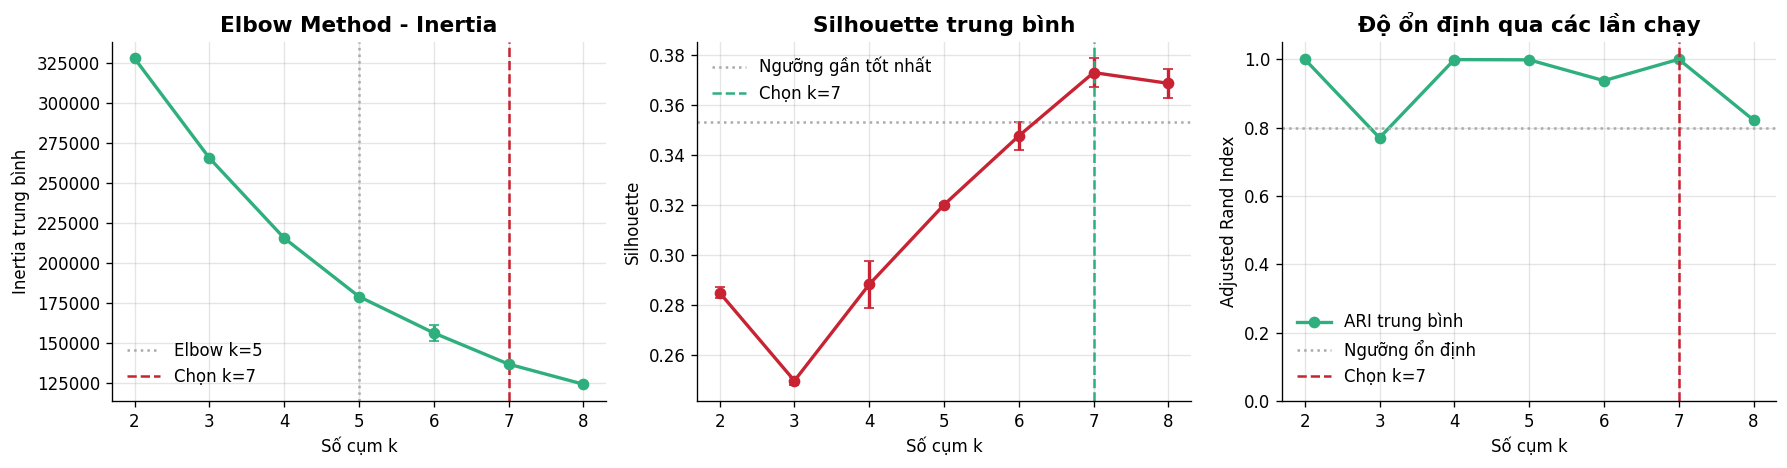

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].errorbar(
    diagnostics["k"], diagnostics["inertia_mean"], yerr=diagnostics["inertia_std"],
    marker="o", color=CLR["sig"], linewidth=2, capsize=3,
)
axes[0].axvline(elbow_k, color=CLR["ns"], linestyle=":", label=f"Elbow k={elbow_k}")
axes[0].axvline(FINAL_K, color=CLR["ngheo"], linestyle="--", label=f"Chọn k={FINAL_K}")
axes[0].set_title("Elbow Method - Inertia", fontweight="bold")
axes[0].set_ylabel("Inertia trung bình")
axes[0].legend(frameon=False)

axes[1].errorbar(
    diagnostics["k"], diagnostics["silhouette_mean"], yerr=diagnostics["silhouette_std"],
    marker="o", color=CLR["ngheo"], linewidth=2, capsize=3,
)
axes[1].axhline(
    diagnostics["silhouette_mean"].max() - SILHOUETTE_TOLERANCE,
    color=CLR["ns"], linestyle=":", label="Ngưỡng gần tốt nhất",
)
axes[1].axvline(FINAL_K, color=CLR["sig"], linestyle="--", label=f"Chọn k={FINAL_K}")
axes[1].set_title("Silhouette trung bình", fontweight="bold")
axes[1].set_ylabel("Silhouette")
axes[1].legend(frameon=False)

axes[2].plot(
    diagnostics["k"], diagnostics["stability_ari_mean"],
    marker="o", color=CLR["sig"], linewidth=2, label="ARI trung bình",
)
axes[2].axhline(MIN_STABILITY_ARI, color=CLR["ns"], linestyle=":", label="Ngưỡng ổn định")
axes[2].axvline(FINAL_K, color=CLR["ngheo"], linestyle="--", label=f"Chọn k={FINAL_K}")
axes[2].set_title("Độ ổn định qua các lần chạy", fontweight="bold")
axes[2].set_ylabel("Adjusted Rand Index")
axes[2].set_ylim(0, 1.05)
axes[2].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("Số cụm k")
    ax.set_xticks(diagnostics["k"])
    ax.grid(color=CLR["ns"], alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


**Nhận xét:** 
- Elbow gợi ý k=5, nhưng k=7 có Silhouette cao nhất khoảng 0,37 và độ ổn định gần 1,0.

**Insight:** 
- Chọn 7 cụm là hợp lý vì các cụm phân tách tốt và ổn định hơn. Tuy nhiên, Silhouette chỉ ở mức trung bình nên giữa các cụm vẫn còn sự giao thoa.

##### 4.5 Train K-Means với k được chọn


In [16]:
labels, centroids, final_inertia = fit_kmeans(scaled, k=FINAL_K, n_init=20)

clustered_df = df.copy()
clustered_df["cluster_id"] = labels

cluster_counts = (
    clustered_df["cluster_id"]
    .value_counts()
    .rename_axis("cluster_id")
    .reset_index(name="so_ho")
    .sort_values("cluster_id")
)
cluster_counts["ty_le_ho"] = (cluster_counts["so_ho"] / len(clustered_df)).round(4)

centroid_df = pd.DataFrame(centroids, columns=FEATURE_COLUMNS)
centroid_df.insert(0, "cluster_id", range(FINAL_K))
centroid_df = centroid_df.round(3)

print(f"K-Means đã train xong với k = {FINAL_K}")
print(f"- Tổng số hộ được gán cụm: {len(clustered_df):,}")
print(f"- Final inertia: {final_inertia:,.2f}")
print("- Phân bố hộ theo cluster_id:")
display(cluster_counts)

print("Tâm cụm trên dữ liệu đã chuẩn hóa (z-score):")
display(centroid_df)


K-Means đã train xong với k = 7
- Tổng số hộ được gán cụm: 26,953
- Final inertia: 137,066.99
- Phân bố hộ theo cluster_id:


,cluster_id,so_ho,ty_le_ho
4,0,2259,0.0838
5,1,2242,0.0832
6,2,1726,0.0640
3,3,2651,0.0984
1,4,5068,0.1880
2,5,4578,0.1699
0,6,8429,0.3127


Tâm cụm trên dữ liệu đã chuẩn hóa (z-score):


,cluster_id,NHAN_KHAU,SO_MAM_NON,SO_HOC_DUONG,SO_LAO_DONG,SO_U50,SO_PHU_THUOC,TY_LE_MAM_NON,TY_LE_HOC_DUONG,TY_LE_LAO_DONG,TY_LE_U50,TY_LE_PHU_THUOC,TUOI_CHU_HO,TUOI_TRUNG_BINH_HO,TUOI_LON_NHAT,TUOI_NHO_NHAT,DO_LECH_TUOI
0,0,-0.962,-0.275,0.213,-1.236,-0.691,-0.246,-0.213,2.183,-1.414,-0.598,0.456,-0.233,-1.263,-1.739,-0.515,-1.231
1,1,-1.057,-0.275,-0.949,-1.286,1.055,-0.332,-0.213,-0.979,-1.493,2.709,0.321,1.466,2.434,1.321,2.753,-1.213
2,2,0.483,3.482,0.247,0.095,-0.439,0.695,2.924,-0.057,-0.352,-0.484,0.541,-0.548,-0.826,-0.543,-0.843,0.239
3,3,1.554,0.048,1.370,0.675,1.005,1.806,-0.104,0.403,-0.345,0.050,1.093,0.438,-0.144,0.868,-0.606,1.405
4,4,0.124,-0.261,-0.666,0.198,1.225,0.021,-0.206,-0.696,0.086,0.736,0.077,0.870,0.621,0.936,0.084,0.842
5,5,-0.824,-0.275,-0.949,-0.127,-0.689,-1.297,-0.213,-0.979,1.326,-0.597,-1.193,-0.393,0.033,-0.483,0.451,-0.895
6,6,0.324,-0.275,0.630,0.392,-0.684,0.135,-0.213,0.510,0.185,-0.595,-0.060,-0.663,-0.486,-0.347,-0.527,0.142


#### 5. Phân tích dữ liệu sau khi phân cụm


#### 5.1 Tổng quan kết quả phân cụm

In [17]:
# Gán tên cụm theo hai đặc trưng nổi bật nhất của chính profile hiện tại.
# Cách này vẫn hoạt động khi FINAL_K thay đổi và không phụ thuộc vào số hiệu nhãn ngẫu nhiên.
CLUSTER_NAME_MAP = {
    0: "Cụm 0 - Áp lực học đường và phụ thuộc cao",
    1: "Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên trẻ",
    2: "Cụm 2 - Áp lực trẻ em mầm non",
    3: "Cụm 3 - Phụ thuộc cao và quy mô hộ lớn",
    4: "Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",
    5: "Cụm 5 - Nguồn lực lao động tương đối tốt, cần phòng tái nghèo",
    6: "Cụm 6 - Nhiều lao động đi kèm áp lực học đường",
}


def assign_cluster_names(profile: pd.DataFrame) -> dict[int, str]:
    return {
        int(cluster_id): CLUSTER_NAME_MAP[int(cluster_id)]
        for cluster_id in profile["cluster_id"]
    }


In [18]:
model_feature_frame = features.copy()
model_feature_frame["cluster_id"] = clustered_df["cluster_id"].to_numpy()

numeric_profile = (
    model_feature_frame.groupby("cluster_id")[FEATURE_COLUMNS]
    .mean()
    .reset_index()
    .round(3)
)
counts = (
    clustered_df["cluster_id"]
    .value_counts()
    .rename_axis("cluster_id")
    .reset_index(name="so_ho")
    .sort_values("cluster_id")
)
counts["ty_le_ho"] = (counts["so_ho"] / len(clustered_df)).round(4)
poverty = pd.crosstab(clustered_df["cluster_id"], clustered_df["PHAN_LOAI_HO"], normalize="index")
poverty = poverty.add_prefix("ty_le_").reset_index().round(4)

profile = counts.merge(numeric_profile, on="cluster_id", how="left").merge(poverty, on="cluster_id", how="left")
cluster_names = assign_cluster_names(profile)
profile["cluster_name"] = profile["cluster_id"].map(cluster_names)
clustered_df["cluster_name"] = clustered_df["cluster_id"].map(cluster_names)

profile = profile[["cluster_id", "cluster_name", "so_ho", "ty_le_ho"] + FEATURE_COLUMNS + [c for c in profile.columns if c.startswith("ty_le_Hộ")]]
summary = pd.DataFrame([
    {"metric": "input_rows", "value": len(df)},
    {"metric": "feature_count", "value": len(FEATURE_COLUMNS)},
    {"metric": "final_k", "value": FINAL_K},
    {"metric": "final_inertia", "value": round(final_inertia, 3)},
    {"metric": "final_silhouette_sample", "value": round(float(diagnostics.loc[diagnostics["k"].eq(FINAL_K), "silhouette_mean"].iloc[0]), 4)},
])

imputation = medians.reset_index()
imputation.columns = ["feature", "median_imputed_value"]

display(summary)
display(profile)


,metric,value
0,input_rows,26953.0000
1,feature_count,16.0000
2,final_k,7.0000
3,final_inertia,137066.9900
4,final_silhouette_sample,0.3731


,cluster_id,cluster_name,so_ho,ty_le_ho,NHAN_KHAU,SO_MAM_NON,SO_HOC_DUONG,SO_LAO_DONG,SO_U50,SO_PHU_THUOC,TY_LE_MAM_NON,TY_LE_HOC_DUONG,TY_LE_LAO_DONG,TY_LE_U50,TY_LE_PHU_THUOC,TUOI_CHU_HO,TUOI_TRUNG_BINH_HO,TUOI_LON_NHAT,TUOI_NHO_NHAT,DO_LECH_TUOI,ty_le_Hộ cận nghèo,ty_le_Hộ nghèo
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,2259,0.0838,1.554,0.000,1.441,0.077,0.000,1.441,0.000,0.962,0.028,0.000,1.441,44.896,11.390,12.293,10.504,1.790,0.4135,0.5865
1,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",2242,0.0832,1.347,0.000,0.000,0.007,1.323,1.323,0.000,0.000,0.002,0.991,1.323,66.056,69.624,70.671,68.518,2.153,0.4349,0.5651
2,2,Cụm 2 - Áp lực trẻ em mầm non,1726,0.0640,4.709,1.056,1.483,1.940,0.191,2.729,0.312,0.280,0.366,0.034,1.515,40.967,18.273,35.103,4.669,30.434,0.4397,0.5603
3,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,2651,0.0984,7.046,0.091,2.874,2.751,1.285,4.250,0.011,0.421,0.368,0.194,1.996,53.249,29.018,62.032,8.872,53.160,0.4059,0.5941
4,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",5068,0.1880,3.925,0.004,0.350,2.083,1.452,1.806,0.001,0.086,0.506,0.400,1.109,58.633,41.064,63.315,21.125,42.190,0.5442,0.4558
5,5,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",4578,0.1699,1.856,0.000,0.000,1.629,0.001,0.001,0.000,0.000,0.901,0.000,0.000,42.900,31.810,36.260,27.652,8.347,0.4838,0.5162
6,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,8429,0.3127,4.361,0.000,1.957,2.355,0.005,1.963,0.000,0.453,0.537,0.001,0.990,39.542,23.634,38.840,10.289,28.547,0.4932,0.5068


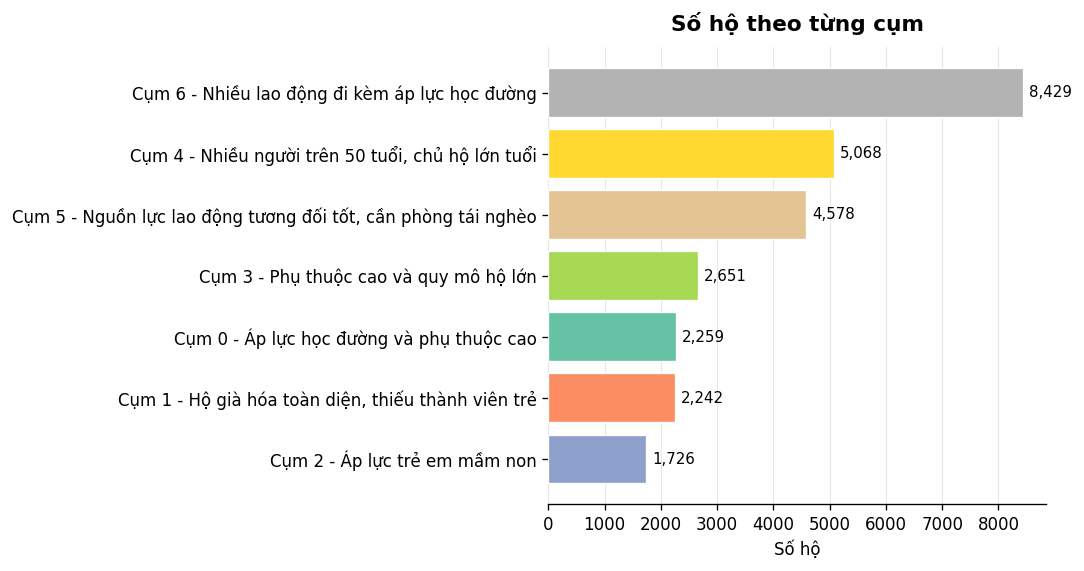

In [19]:
cluster_size_df = profile[["cluster_name", "so_ho"]].copy().sort_values("so_ho", ascending=True)
palette = plt.cm.Set2(np.linspace(0, 1, max(FINAL_K, 3)))
cluster_colors = dict(zip(profile["cluster_name"], palette))
colors = cluster_size_df["cluster_name"].map(cluster_colors)

fig, ax = plt.subplots(figsize=(9, max(4.2, 0.48 * FINAL_K + 1.5)))
bars = ax.barh(cluster_size_df["cluster_name"], cluster_size_df["so_ho"], color=list(colors), edgecolor="white", linewidth=0.8)
ax.set_title("Số hộ theo từng cụm", pad=10, fontweight="bold")
ax.set_xlabel("Số hộ")
ax.grid(axis="x", color=CLR["ns"], alpha=0.28, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=9)
plt.tight_layout()
plt.show()


**Nhận xét:**
- Cụm 6 chiếm nhiều nhất với 8.429 hộ, vượt xa các cụm còn lại, cho thấy nhóm hộ có nhiều lao động và người đi học là cấu trúc phổ biến nhất. Cụm 2 ít nhất với 1.726 hộ, phản ánh nhóm có nhiều trẻ mầm non chỉ chiếm tỷ trọng nhỏ.

#### 5.2 Profile đặc trưng của từng cụm

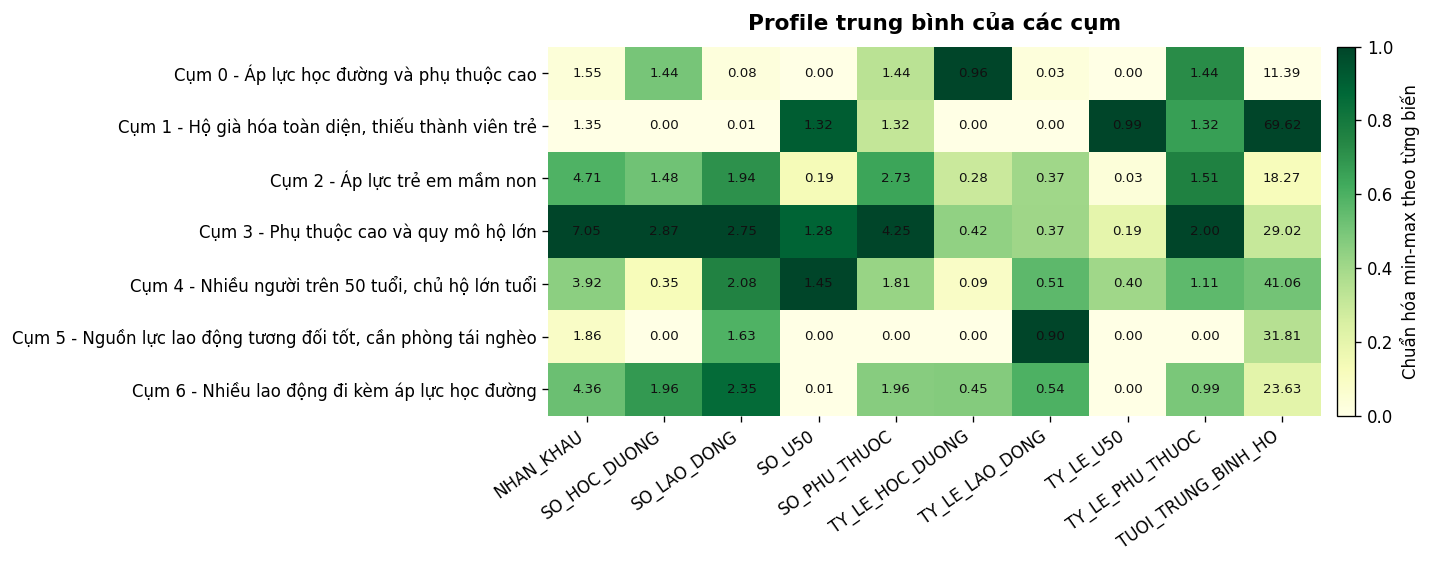

In [20]:
profile_features = [
    "NHAN_KHAU", "SO_HOC_DUONG", "SO_LAO_DONG", "SO_U50", "SO_PHU_THUOC",
    "TY_LE_HOC_DUONG", "TY_LE_LAO_DONG", "TY_LE_U50", "TY_LE_PHU_THUOC", "TUOI_TRUNG_BINH_HO",
]
heatmap_df = profile.set_index("cluster_name")[profile_features].apply(pd.to_numeric, errors="coerce")
scaled_heatmap = (heatmap_df - heatmap_df.min()) / (heatmap_df.max() - heatmap_df.min()).replace(0, 1)

fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(scaled_heatmap, aspect="auto", cmap="YlGn", vmin=0, vmax=1)
ax.set_title("Profile trung bình của các cụm", pad=10, fontweight="bold")
ax.set_xticks(np.arange(len(profile_features)))
ax.set_xticklabels(profile_features, rotation=35, ha="right")
ax.set_yticks(np.arange(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)

for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        ax.text(j, i, f"{heatmap_df.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="#111111")

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Chuẩn hóa min-max theo từng biến")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()


#### 5.3 Liên hệ với hộ nghèo/cận nghèo và địa bàn

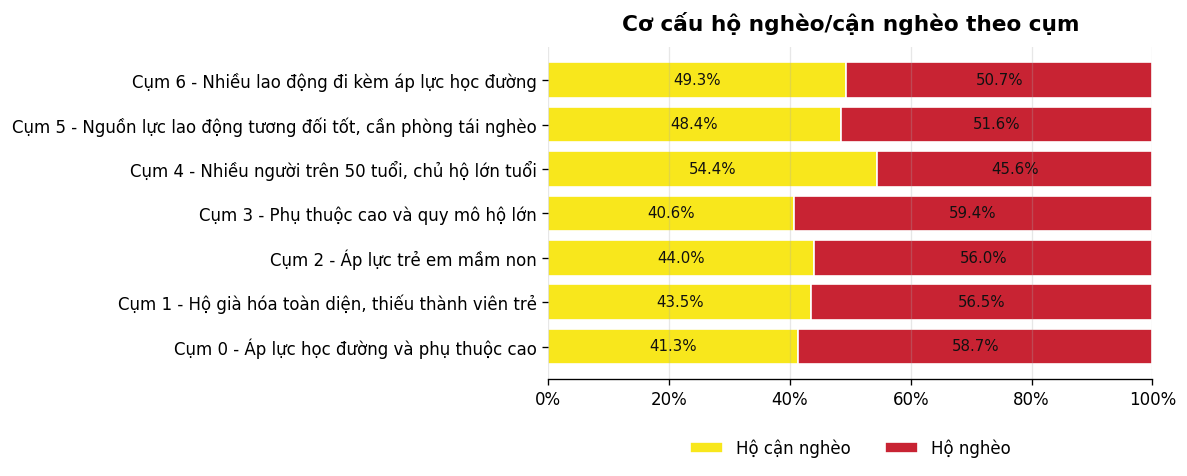

In [21]:
poverty_cols = [col for col in profile.columns if col.startswith("ty_le_Hộ")]
poverty_df = profile.set_index("cluster_name")[poverty_cols].copy()
poverty_colors = [CLR["can"] if "cận" in col.lower() else CLR["ngheo"] for col in poverty_cols]

fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(poverty_df))
y = np.arange(len(poverty_df))
for col, color in zip(poverty_cols, poverty_colors):
    values = poverty_df[col].to_numpy(dtype=float)
    bars = ax.barh(y, values, left=left, color=color, edgecolor="white", label=col.replace("ty_le_", ""))
    for bar, value, start in zip(bars, values, left):
        if value >= 0.08:
            ax.text(start + value / 2, bar.get_y() + bar.get_height() / 2, f"{value:.1%}", ha="center", va="center", fontsize=9, color="#111111")
    left += values

ax.set_yticks(y)
ax.set_yticklabels(poverty_df.index)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Cơ cấu hộ nghèo/cận nghèo theo cụm", pad=10, fontweight="bold")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.28), ncol=len(poverty_cols), frameon=False)
ax.grid(axis="x", color=CLR["ns"], alpha=0.28)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()


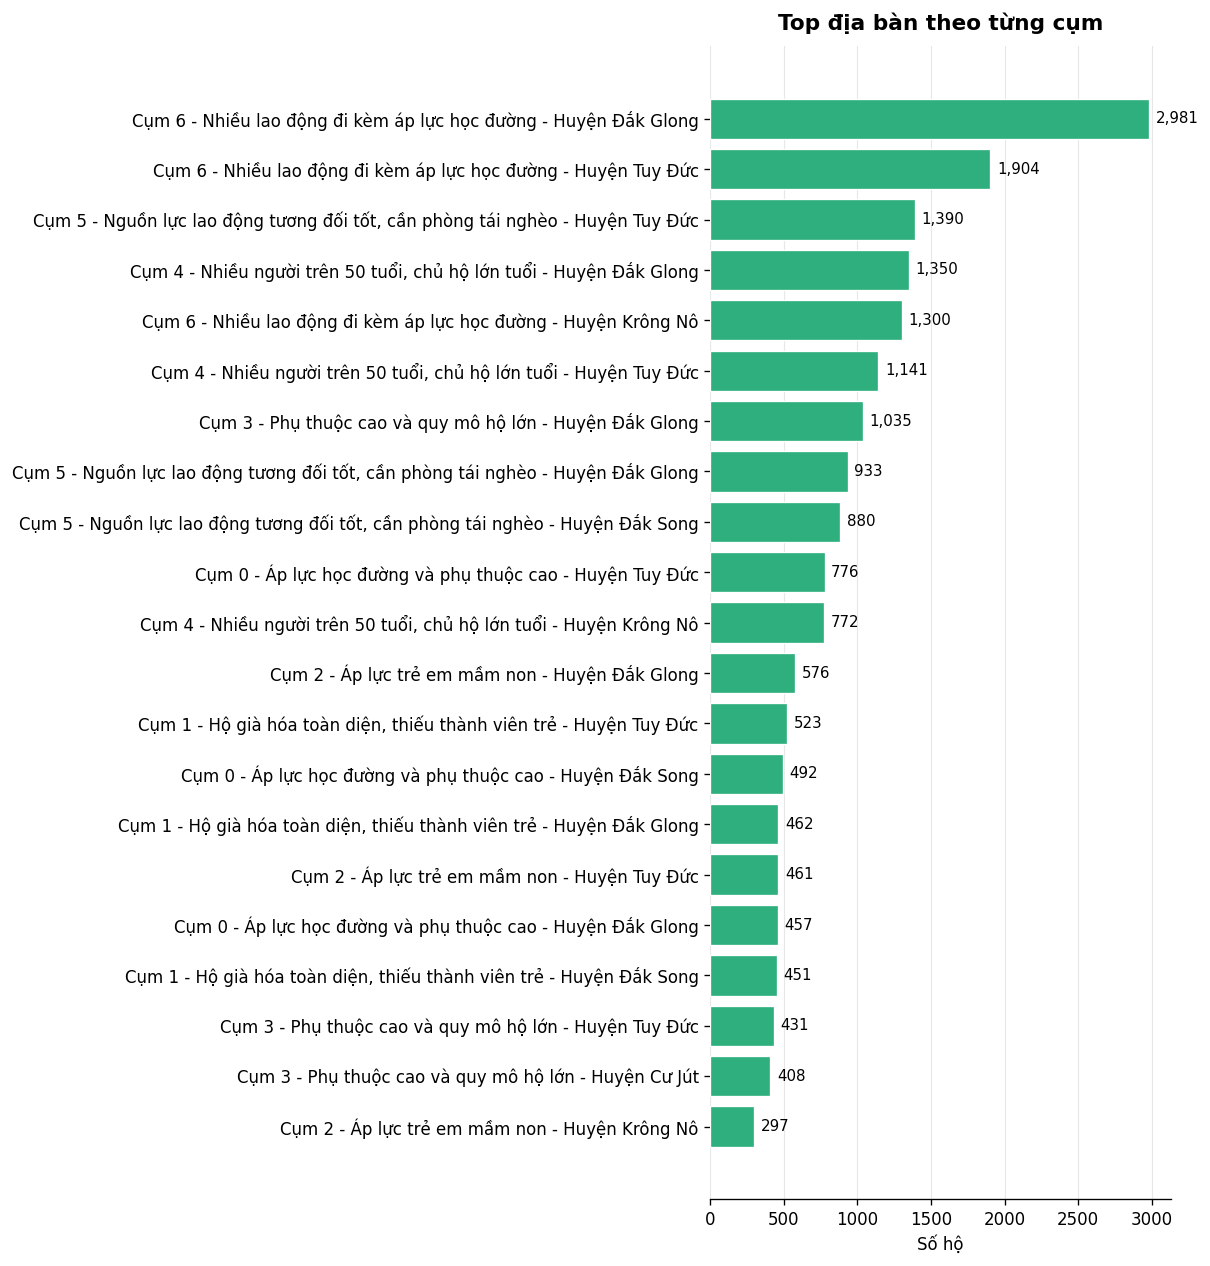

,cluster_id,cluster_name,HUYEN,so_ho
2,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Tuy Đức,776
6,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Đắk Song,492
3,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Đắk Glong,457
1,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Krông Nô,232
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Cư Jút,132
4,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Đắk Mil,96
5,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Huyện Đắk R'lấp,44
7,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,Thành phố Gia Nghĩa,30
10,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",Huyện Tuy Đức,523
11,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",Huyện Đắk Glong,462


In [22]:
district_profile = (
    clustered_df.groupby(["cluster_id", "cluster_name", "HUYEN"])
    .size()
    .reset_index(name="so_ho")
    .sort_values(["cluster_id", "so_ho"], ascending=[True, False])
)

top_district_df = (
    district_profile.groupby("cluster_name")
    .head(3)
    .assign(label=lambda d: d["cluster_name"] + " - " + d["HUYEN"])
    .sort_values("so_ho", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, max(4.5, 0.45 * len(top_district_df) + 1.2)))
bars = ax.barh(top_district_df["label"], top_district_df["so_ho"], color=CLR["sig"], edgecolor="white", linewidth=0.8)
ax.set_title("Top địa bàn theo từng cụm", pad=10, fontweight="bold")
ax.set_xlabel("Số hộ")
ax.grid(axis="x", color=CLR["ns"], alpha=0.28, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=9)
plt.tight_layout()
plt.show()

display(district_profile.head(20))


##### 5.4 Kiểm tra nhóm có giá trị bất thường sau phân cụm

In [23]:
outlier_check_cols = [
    "NHAN_KHAU", "SO_HOC_DUONG", "SO_LAO_DONG", "SO_U50", "SO_PHU_THUOC",
    "TY_LE_PHU_THUOC", "TUOI_CHU_HO", "TUOI_TRUNG_BINH_HO",
]
outlier_check_cols = [col for col in outlier_check_cols if col in features.columns]

outlier_thresholds = []
outlier_detail_frames = []
outlier_mask = pd.Series(False, index=features.index)

for col in outlier_check_cols:
    q1 = features[col].quantile(0.25)
    q3 = features[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    col_mask = features[col].lt(lower) | features[col].gt(upper)
    outlier_mask |= col_mask

    outlier_thresholds.append({
        "bien_bat_thuong": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "nguong_duoi": lower,
        "nguong_tren": upper,
        "so_ho_bat_thuong": int(col_mask.sum()),
    })

    if col_mask.any():
        detail = clustered_df.loc[col_mask, [c for c in ID_COLUMNS if c in clustered_df.columns] + ["cluster_id", "cluster_name"]].copy()
        detail["bien_bat_thuong"] = col
        detail["gia_tri"] = features.loc[col_mask, col].to_numpy()
        detail["nguong_duoi"] = lower
        detail["nguong_tren"] = upper
        detail["huong_bat_thuong"] = np.where(detail["gia_tri"].lt(lower), "thap hon nguong", "cao hon nguong")
        outlier_detail_frames.append(detail)

clustered_df["co_gia_tri_bat_thuong"] = outlier_mask
outlier_thresholds_df = pd.DataFrame(outlier_thresholds).round(4)
outlier_detail = pd.concat(outlier_detail_frames, ignore_index=True) if outlier_detail_frames else pd.DataFrame()

outlier_profile = (
    clustered_df.groupby(["cluster_id", "cluster_name"])["co_gia_tri_bat_thuong"]
    .agg(so_ho_bat_thuong="sum", tong_so_ho="count")
    .reset_index()
)
outlier_profile["ty_le_bat_thuong"] = (outlier_profile["so_ho_bat_thuong"] / outlier_profile["tong_so_ho"]).round(4)

outlier_by_variable = (
    outlier_detail.groupby(["cluster_id", "cluster_name", "bien_bat_thuong", "huong_bat_thuong"])
    .size()
    .reset_index(name="so_luot_bat_thuong")
    .sort_values(["cluster_id", "so_luot_bat_thuong"], ascending=[True, False])
)

print("Tong hop ho co it nhat mot gia tri bat thuong theo cum:")
display(outlier_profile)

print("Nguong IQR dung de xac dinh bat thuong theo tung bien:")
display(outlier_thresholds_df)

print("Cac bien bat thuong noi bat theo tung cum:")
display(outlier_by_variable.head(10))

print("Mot so dong chi tiet: ho nao bat thuong, bat thuong o bien nao, gia tri bao nhieu:")
display(outlier_detail.head(10))


Tong hop ho co it nhat mot gia tri bat thuong theo cum:


,cluster_id,cluster_name,so_ho_bat_thuong,tong_so_ho,ty_le_bat_thuong
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,70,2259,0.0310
1,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",1752,2242,0.7814
2,2,Cụm 2 - Áp lực trẻ em mầm non,432,1726,0.2503
3,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,1965,2651,0.7412
4,4,"Cụm 4 - Nhiều người trên 50 tuổi, chủ hộ lớn tuổi",644,5068,0.1271
5,5,"Cụm 5 - Nguồn lực lao động tương đối tốt, cần ...",7,4578,0.0015
6,6,Cụm 6 - Nhiều lao động đi kèm áp lực học đường,455,8429,0.0540


Nguong IQR dung de xac dinh bat thuong theo tung bien:


,bien_bat_thuong,q1,q3,iqr,nguong_duoi,nguong_tren,so_ho_bat_thuong
0,NHAN_KHAU,2.0,5.0,3.0,-2.5,9.5,376
1,SO_HOC_DUONG,0.0,2.0,2.0,-3.0,5.0,89
2,SO_LAO_DONG,1.0,3.0,2.0,-2.0,6.0,118
3,SO_U50,0.0,1.0,1.0,-1.5,2.5,167
4,SO_PHU_THUOC,1.0,2.0,1.0,-0.5,3.5,2800
5,TY_LE_PHU_THUOC,0.5,1.5,1.0,-1.0,3.0,506
6,TUOI_CHU_HO,40.0,53.0,13.0,20.5,72.5,1599
7,TUOI_TRUNG_BINH_HO,21.4,37.0,15.6,-2.0,60.4,1875


Cac bien bat thuong noi bat theo tung cum:


,cluster_id,cluster_name,bien_bat_thuong,huong_bat_thuong,so_luot_bat_thuong
0,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,SO_PHU_THUOC,cao hon nguong,63
2,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,TY_LE_PHU_THUOC,cao hon nguong,63
1,0,Cụm 0 - Áp lực học đường và phụ thuộc cao,TUOI_CHU_HO,thap hon nguong,7
6,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",TUOI_TRUNG_BINH_HO,cao hon nguong,1751
5,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",TUOI_CHU_HO,cao hon nguong,822
4,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",SO_U50,cao hon nguong,25
3,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",SO_PHU_THUOC,cao hon nguong,1
7,1,"Cụm 1 - Hộ già hóa toàn diện, thiếu thành viên...",TY_LE_PHU_THUOC,cao hon nguong,1
11,2,Cụm 2 - Áp lực trẻ em mầm non,SO_PHU_THUOC,cao hon nguong,411
15,2,Cụm 2 - Áp lực trẻ em mầm non,TY_LE_PHU_THUOC,cao hon nguong,69


Mot so dong chi tiet: ho nao bat thuong, bat thuong o bien nao, gia tri bao nhieu:


,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,HO_TEN_CHU_HO,cluster_id,cluster_name,bien_bat_thuong,gia_tri,nguong_duoi,nguong_tren,huong_bat_thuong
0,70,70,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,Y BUN ÊBAN,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,NHAN_KHAU,12.0,-2.5,9.5,cao hon nguong
1,213,210,Huyện Cư Jút,EAT'LING,Hộ nghèo,Y KHER KPƠR,2,Cụm 2 - Áp lực trẻ em mầm non,NHAN_KHAU,10.0,-2.5,9.5,cao hon nguong
2,215,212,Huyện Cư Jút,EAT'LING,Hộ nghèo,Y DÃN KTUL,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,NHAN_KHAU,11.0,-2.5,9.5,cao hon nguong
3,216,213,Huyện Cư Jút,EAT'LING,Hộ nghèo,Y GRƠNG YA,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,NHAN_KHAU,10.0,-2.5,9.5,cao hon nguong
4,395,391,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,HOÀNG THỊ KE,2,Cụm 2 - Áp lực trẻ em mầm non,NHAN_KHAU,14.0,-2.5,9.5,cao hon nguong
5,398,394,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,SẰM VĂN SÓ,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,NHAN_KHAU,10.0,-2.5,9.5,cao hon nguong
6,411,407,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,HOÀNG VĂN TU (B),2,Cụm 2 - Áp lực trẻ em mầm non,NHAN_KHAU,10.0,-2.5,9.5,cao hon nguong
7,422,418,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,LẦU VĂN SÙNG,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,NHAN_KHAU,13.0,-2.5,9.5,cao hon nguong
8,440,436,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,LÝ A PÁO,3,Cụm 3 - Phụ thuộc cao và quy mô hộ lớn,NHAN_KHAU,15.0,-2.5,9.5,cao hon nguong
9,446,442,Huyện Cư Jút,ĐẮK D'RÔNG,Hộ nghèo,CHANG VĂN HẦU,2,Cụm 2 - Áp lực trẻ em mầm non,NHAN_KHAU,13.0,-2.5,9.5,cao hon nguong


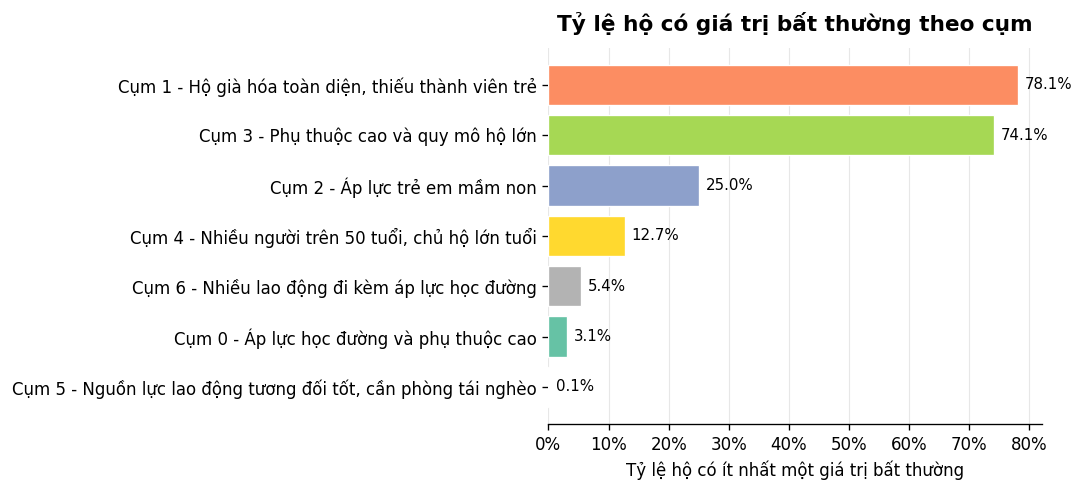

In [24]:
outlier_plot_df = outlier_profile.sort_values("ty_le_bat_thuong", ascending=True)
colors = outlier_plot_df["cluster_name"].map(cluster_colors).fillna(CLR["ns"])

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(outlier_plot_df["cluster_name"], outlier_plot_df["ty_le_bat_thuong"], color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Tỷ lệ hộ có giá trị bất thường theo cụm", pad=10, fontweight="bold")
ax.set_xlabel("Tỷ lệ hộ có ít nhất một giá trị bất thường")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="x", color=CLR["ns"], alpha=0.28, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in outlier_plot_df["ty_le_bat_thuong"]], padding=4, fontsize=9)
plt.tight_layout()
plt.show()


#### 6. Ghi lại dữ liệu

In [25]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_columns = [col for col in ID_COLUMNS if col in clustered_df.columns]
exclude_output_columns = ["co_gia_tri_bat_thuong"]
remaining_columns = [col for col in clustered_df.columns if col not in output_columns and col not in exclude_output_columns]
clustered_output = clustered_df[output_columns + remaining_columns]

try:
    clustered_output.to_excel(CLUSTERED_PATH, sheet_name="clustered", index=False)
except PermissionError as exc:
    raise PermissionError(f"{CLUSTERED_PATH}") from exc

try:
    with pd.ExcelWriter(PROFILE_PATH, engine="openpyxl") as writer:
        profile.to_excel(writer, sheet_name="cluster_profile", index=False)
        district_profile.to_excel(writer, sheet_name="cluster_by_district", index=False)
        diagnostics.to_excel(writer, sheet_name="kmeans_diagnostics", index=False)
        imputation.to_excel(writer, sheet_name="imputation_medians", index=False)
        summary.to_excel(writer, sheet_name="summary", index=False)
        outlier_profile.to_excel(writer, sheet_name="outlier_profile", index=False)
        outlier_thresholds_df.to_excel(writer, sheet_name="outlier_thresholds", index=False)
        outlier_by_variable.to_excel(writer, sheet_name="outlier_by_variable", index=False)
        outlier_detail.to_excel(writer, sheet_name="outlier_detail", index=False)
except PermissionError as exc:
    raise PermissionError(f"{PROFILE_PATH}") from exc

print("Đã ghi output:")
print(CLUSTERED_PATH)
print(PROFILE_PATH)


Đã ghi output:
C:\NguyenHoangThanhTam\data\model\household_clustered.xlsx
C:\NguyenHoangThanhTam\data\model\cluster_profile.xlsx


#### **Kết luận**

- Notebook thử toàn bộ `k=2–8`, mỗi giá trị được fit nhiều lần với seed khác nhau.
- Quyết định kết hợp bốn bằng chứng: điểm elbow của Inertia, Silhouette trung bình, độ ổn định ARI và tỷ lệ của cụm nhỏ nhất.
- `FINAL_K` được sinh trực tiếp từ quy tắc đã công bố trong phần 4.3. 
- Sau khi chọn k, tên cụm được tạo từ profile hiện tại để tránh gắn ý nghĩa cố định vào số hiệu nhãn vốn có thể hoán đổi giữa các lần chạy.
